In [1]:
print("Python EDA and Decision Tree Assignment")
print("Predicting Student Academic Risk in a Kenyan University")
print("Notebook setup successful!")

Python EDA and Decision Tree Assignment
Predicting Student Academic Risk in a Kenyan University
Notebook setup successful!


In [2]:
import pandas as pd

raw_data = {
    'Student_ID': [1001, 1002, 1003, 1004, 1005, 1001, 1006, 1007, 1008, 1009],
    'County': ['Nakuru', 'Narok', 'Nakuru', 'Narok', 'Kakamega',
               'Nakuru', 'Nairobi', None, 'Narok', 'Nakuru'],
    'Study_Hours_Per_Week': [15, 8, 20, None, 12, 15, 30, 10, 25, 18],
    'Attendance_Percent': [85, 60, 92, 55, 78, 85, 95, 65, 88, None],
    'Fee_Balance_Ksh': [0, 15000, 0, 25000, 5000, 0, 0, 18000, 2000, 12000],
    'Previous_Grade': [72, 48, 85, 45, 65, 72, 90, 50, 82, 58],
    'Student_Type': ['Regular', 'Regular', 'Scholarship', 'Regular',
                     'Scholarship', 'Regular', 'Regular', 'Scholarship',
                     'Regular', 'Regular'],
    'Academic_Risk': [0, 1, 0, 1, 0, 0, 0, 1, 0, 1]
}

df = pd.DataFrame(raw_data)

df

,Student_ID,County,Study_Hours_Per_Week,Attendance_Percent,Fee_Balance_Ksh,Previous_Grade,Student_Type,Academic_Risk
0,1001,Nakuru,15.0,85.0,0,72,Regular,0
1,1002,Narok,8.0,60.0,15000,48,Regular,1
2,1003,Nakuru,20.0,92.0,0,85,Scholarship,0
3,1004,Narok,NaN,55.0,25000,45,Regular,1
4,1005,Kakamega,12.0,78.0,5000,65,Scholarship,0
5,1001,Nakuru,15.0,85.0,0,72,Regular,0
6,1006,Nairobi,30.0,95.0,0,90,Regular,0
7,1007,None,10.0,65.0,18000,50,Scholarship,1
8,1008,Narok,25.0,88.0,2000,82,Regular,0
9,1009,Nakuru,18.0,NaN,12000,58,Regular,1


In [3]:
df.shape

(10, 8)

In [4]:
df.dtypes

Student_ID                int64
County                   object
Study_Hours_Per_Week    float64
Attendance_Percent      float64
Fee_Balance_Ksh           int64
Previous_Grade            int64
Student_Type             object
Academic_Risk             int64
dtype: object

In [5]:
df.describe()

,Student_ID,Study_Hours_Per_Week,Attendance_Percent,Fee_Balance_Ksh,Previous_Grade,Academic_Risk
count,10.000000,9.000000,9.000000,10.000000,10.000000,10.000000
mean,1004.600000,17.000000,78.111111,7700.000000,66.700000,0.400000
std,2.875181,7.123903,14.598326,9153.627089,16.145519,0.516398
min,1001.000000,8.000000,55.000000,0.000000,45.000000,0.000000
25%,1002.250000,12.000000,65.000000,0.000000,52.000000,0.000000
50%,1004.500000,15.000000,85.000000,3500.000000,68.500000,0.000000
75%,1006.750000,20.000000,88.000000,14250.000000,79.500000,1.000000
max,1009.000000,30.000000,95.000000,25000.000000,90.000000,1.000000


In [6]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10 entries, 0 to 9
Data columns (total 8 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   Student_ID            10 non-null     int64  
 1   County                9 non-null      object 
 2   Study_Hours_Per_Week  9 non-null      float64
 3   Attendance_Percent    9 non-null      float64
 4   Fee_Balance_Ksh       10 non-null     int64  
 5   Previous_Grade        10 non-null     int64  
 6   Student_Type          10 non-null     object 
 7   Academic_Risk         10 non-null     int64  
dtypes: float64(2), int64(4), object(2)
memory usage: 772.0+ bytes


In [7]:
df.duplicated()

0    False
1    False
2    False
3    False
4    False
5     True
6    False
7    False
8    False
9    False
dtype: bool

In [8]:
df.duplicated().sum()

np.int64(1)

In [9]:
df.isnull().sum()

Student_ID              0
County                  1
Study_Hours_Per_Week    1
Attendance_Percent      1
Fee_Balance_Ksh         0
Previous_Grade          0
Student_Type            0
Academic_Risk           0
dtype: int64

In [10]:
df[df.isnull().any(axis=1)]

,Student_ID,County,Study_Hours_Per_Week,Attendance_Percent,Fee_Balance_Ksh,Previous_Grade,Student_Type,Academic_Risk
3,1004,Narok,NaN,55.0,25000,45,Regular,1
7,1007,None,10.0,65.0,18000,50,Scholarship,1
9,1009,Nakuru,18.0,NaN,12000,58,Regular,1


In [11]:
df=df.drop_duplicates()

In [12]:
df.shape

(9, 8)

In [17]:
df = df.copy()

In [18]:
df.loc[:, 'County'] = df['County'].fillna(
    df['County'].mode()[0]
)
df.loc[:, 'Study_Hours_Per_Week'] = df['Study_Hours_Per_Week'].fillna(
    df['Study_Hours_Per_Week'].median()
)
df.loc[:, 'Attendance_Percent'] = df['Attendance_Percent'].fillna(
    df['Attendance_Percent'].median()
)
df.isnull().sum()

Student_ID              0
County                  0
Study_Hours_Per_Week    0
Attendance_Percent      0
Fee_Balance_Ksh         0
Previous_Grade          0
Student_Type            0
Academic_Risk           0
dtype: int64

In [19]:
print("Dataset shape:", df.shape)
print("Total duplicate rows:", df.duplicated().sum())
print("Total missing values:", df.isnull().sum().sum())

df

Dataset shape: (9, 8)
Total duplicate rows: 0
Total missing values: 0


,Student_ID,County,Study_Hours_Per_Week,Attendance_Percent,Fee_Balance_Ksh,Previous_Grade,Student_Type,Academic_Risk
0,1001,Nakuru,15.0,85.0,0,72,Regular,0
1,1002,Narok,8.0,60.0,15000,48,Regular,1
2,1003,Nakuru,20.0,92.0,0,85,Scholarship,0
3,1004,Narok,16.5,55.0,25000,45,Regular,1
4,1005,Kakamega,12.0,78.0,5000,65,Scholarship,0
6,1006,Nairobi,30.0,95.0,0,90,Regular,0
7,1007,Nakuru,10.0,65.0,18000,50,Scholarship,1
8,1008,Narok,25.0,88.0,2000,82,Regular,0
9,1009,Nakuru,18.0,81.5,12000,58,Regular,1


In [20]:
import matplotlib.pyplot as plt
import seaborn as sns
sns.set_theme(style="whitegrid")

print("Libraries imported successfully!")

Libraries imported successfully!


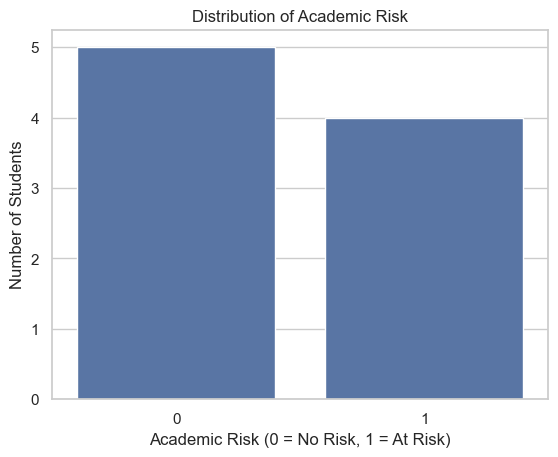

In [21]:
sns.countplot(data=df, x='Academic_Risk')

plt.title('Distribution of Academic Risk')
plt.xlabel('Academic Risk (0 = No Risk, 1 = At Risk)')
plt.ylabel('Number of Students')
plt.show()

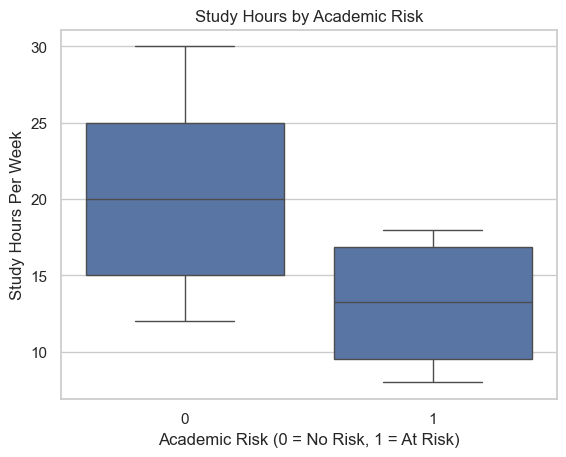

In [22]:
sns.boxplot(data=df, x='Academic_Risk', y='Study_Hours_Per_Week')

plt.title('Study Hours by Academic Risk')
plt.xlabel('Academic Risk (0 = No Risk, 1 = At Risk)')
plt.ylabel('Study Hours Per Week')
plt.show()

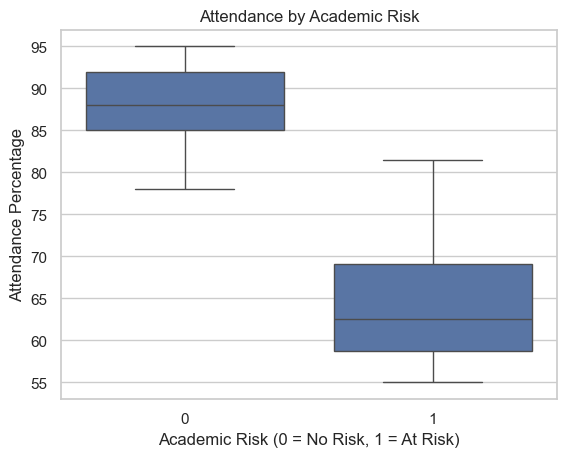

In [23]:
sns.boxplot(data=df, x='Academic_Risk', y='Attendance_Percent')

plt.title('Attendance by Academic Risk')
plt.xlabel('Academic Risk (0 = No Risk, 1 = At Risk)')
plt.ylabel('Attendance Percentage')
plt.show()

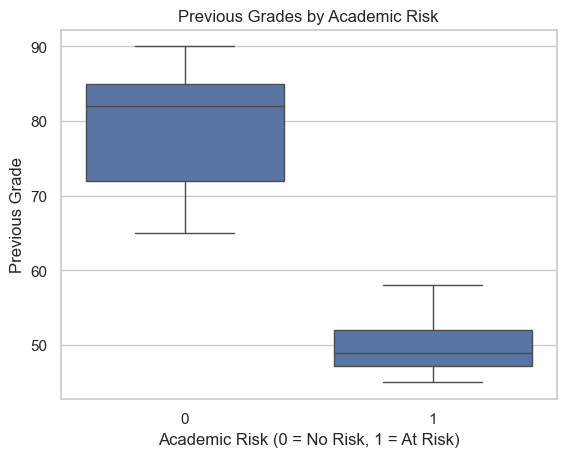

In [24]:
sns.boxplot(data=df, x='Academic_Risk', y='Previous_Grade')

plt.title('Previous Grades by Academic Risk')
plt.xlabel('Academic Risk (0 = No Risk, 1 = At Risk)')
plt.ylabel('Previous Grade')
plt.show()

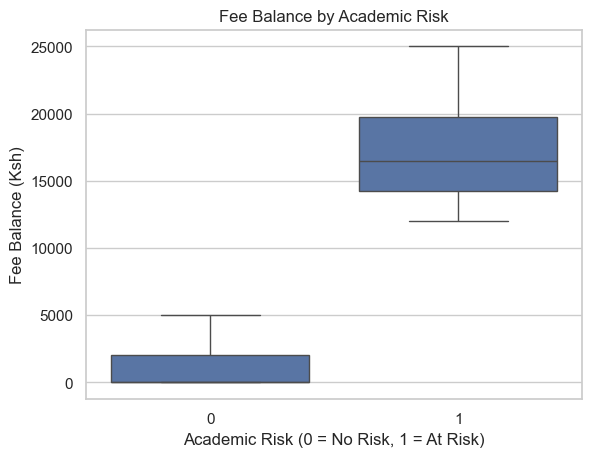

In [25]:
sns.boxplot(data=df, x='Academic_Risk', y='Fee_Balance_Ksh')

plt.title('Fee Balance by Academic Risk')
plt.xlabel('Academic Risk (0 = No Risk, 1 = At Risk)')
plt.ylabel('Fee Balance (Ksh)')
plt.show()

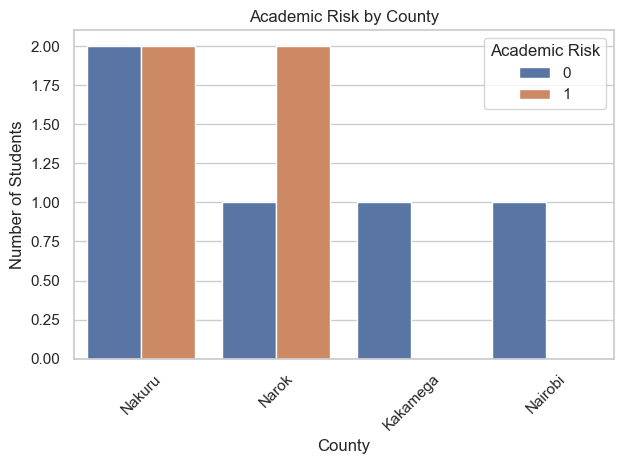

In [26]:
sns.countplot(data=df, x='County', hue='Academic_Risk')

plt.title('Academic Risk by County')
plt.xlabel('County')
plt.ylabel('Number of Students')
plt.xticks(rotation=45)
plt.legend(title='Academic Risk')
plt.tight_layout()
plt.show()

In [27]:
def categorize_attendance(attendance):
    if attendance >= 80:
        return 'High'
    elif attendance >= 60:
        return 'Moderate'
    else:
        return 'Low'

df['Attendance_Category'] = df['Attendance_Percent'].apply(
    categorize_attendance
)

df[['Attendance_Percent', 'Attendance_Category']]

,Attendance_Percent,Attendance_Category
0,85.0,High
1,60.0,Moderate
2,92.0,High
3,55.0,Low
4,78.0,Moderate
6,95.0,High
7,65.0,Moderate
8,88.0,High
9,81.5,High


In [28]:
df['Has_Fee_Balance'] = df['Fee_Balance_Ksh'].apply(
    lambda balance: 1 if balance > 0 else 0
)

df[['Fee_Balance_Ksh', 'Has_Fee_Balance']]

,Fee_Balance_Ksh,Has_Fee_Balance
0,0,0
1,15000,1
2,0,0
3,25000,1
4,5000,1
6,0,0
7,18000,1
8,2000,1
9,12000,1


In [29]:
df.head()

,Student_ID,County,Study_Hours_Per_Week,Attendance_Percent,Fee_Balance_Ksh,Previous_Grade,Student_Type,Academic_Risk,Attendance_Category,Has_Fee_Balance
0,1001,Nakuru,15.0,85.0,0,72,Regular,0,High,0
1,1002,Narok,8.0,60.0,15000,48,Regular,1,Moderate,1
2,1003,Nakuru,20.0,92.0,0,85,Scholarship,0,High,0
3,1004,Narok,16.5,55.0,25000,45,Regular,1,Low,1
4,1005,Kakamega,12.0,78.0,5000,65,Scholarship,0,Moderate,1


In [30]:
import pandas as pd
from sklearn.preprocessing import StandardScaler

print("Libraries imported successfully!")

Libraries imported successfully!


In [31]:
df_encoded = pd.get_dummies(
    df,
    columns=['County', 'Student_Type'],
    dtype=int
)

df_encoded.head()

,Student_ID,Study_Hours_Per_Week,Attendance_Percent,Fee_Balance_Ksh,Previous_Grade,Academic_Risk,Attendance_Category,Has_Fee_Balance,County_Kakamega,County_Nairobi,County_Nakuru,County_Narok,Student_Type_Regular,Student_Type_Scholarship
0,1001,15.0,85.0,0,72,0,High,0,0,0,1,0,1,0
1,1002,8.0,60.0,15000,48,1,Moderate,1,0,0,0,1,1,0
2,1003,20.0,92.0,0,85,0,High,0,0,0,1,0,0,1
3,1004,16.5,55.0,25000,45,1,Low,1,0,0,0,1,1,0
4,1005,12.0,78.0,5000,65,0,Moderate,1,1,0,0,0,0,1


In [32]:
numeric_cols = [
    'Study_Hours_Per_Week',
    'Attendance_Percent',
    'Fee_Balance_Ksh',
    'Previous_Grade'
]
df_scaled = df_encoded.copy()
scaler = StandardScaler()
df_scaled[numeric_cols] = scaler.fit_transform(
    df_scaled[numeric_cols]
)
df_scaled.head()

,Student_ID,Study_Hours_Per_Week,Attendance_Percent,Fee_Balance_Ksh,Previous_Grade,Academic_Risk,Attendance_Category,Has_Fee_Balance,County_Kakamega,County_Nairobi,County_Nakuru,County_Narok,Student_Type_Regular,Student_Type_Scholarship
0,1001,-0.324191,0.534663,-0.978374,0.367189,0,High,0,0,0,1,0,1,0
1,1002,-1.371575,-1.301965,0.736957,-1.129279,1,Moderate,1,0,0,0,1,1,0
2,1003,0.423941,1.048918,-0.978374,1.177776,0,High,0,0,0,1,0,0,1
3,1004,-0.099751,-1.669290,1.880512,-1.316338,1,Low,1,0,0,0,1,1,0
4,1005,-0.773070,0.020407,-0.406597,-0.069281,0,Moderate,1,1,0,0,0,0,1


In [33]:
df_scaled[numeric_cols].agg(['mean', 'std']).round(3)

,Study_Hours_Per_Week,Attendance_Percent,Fee_Balance_Ksh,Previous_Grade
mean,-0.000,-0.000,0.000,-0.000
std,1.061,1.061,1.061,1.061


In [34]:
corr_data = df.select_dtypes(include='number')
correlation_matrix = corr_data.corr()

correlation_matrix

,Student_ID,Study_Hours_Per_Week,Attendance_Percent,Fee_Balance_Ksh,Previous_Grade,Academic_Risk,Has_Fee_Balance
Student_ID,1.000000,0.363798,0.177040,0.098422,0.056348,0.173205,0.456435
Study_Hours_Per_Week,0.363798,1.000000,0.729666,-0.538667,0.794401,-0.540896,-0.476108
Attendance_Percent,0.177040,0.729666,1.000000,-0.929363,0.948358,-0.811326,-0.672434
Fee_Balance_Ksh,0.098422,-0.538667,-0.929363,1.000000,-0.919468,0.914861,0.691815
Previous_Grade,0.056348,0.794401,0.948358,-0.919468,1.000000,-0.884575,-0.715240
Academic_Risk,0.173205,-0.540896,-0.811326,0.914861,-0.884575,1.000000,0.632456
Has_Fee_Balance,0.456435,-0.476108,-0.672434,0.691815,-0.715240,0.632456,1.000000


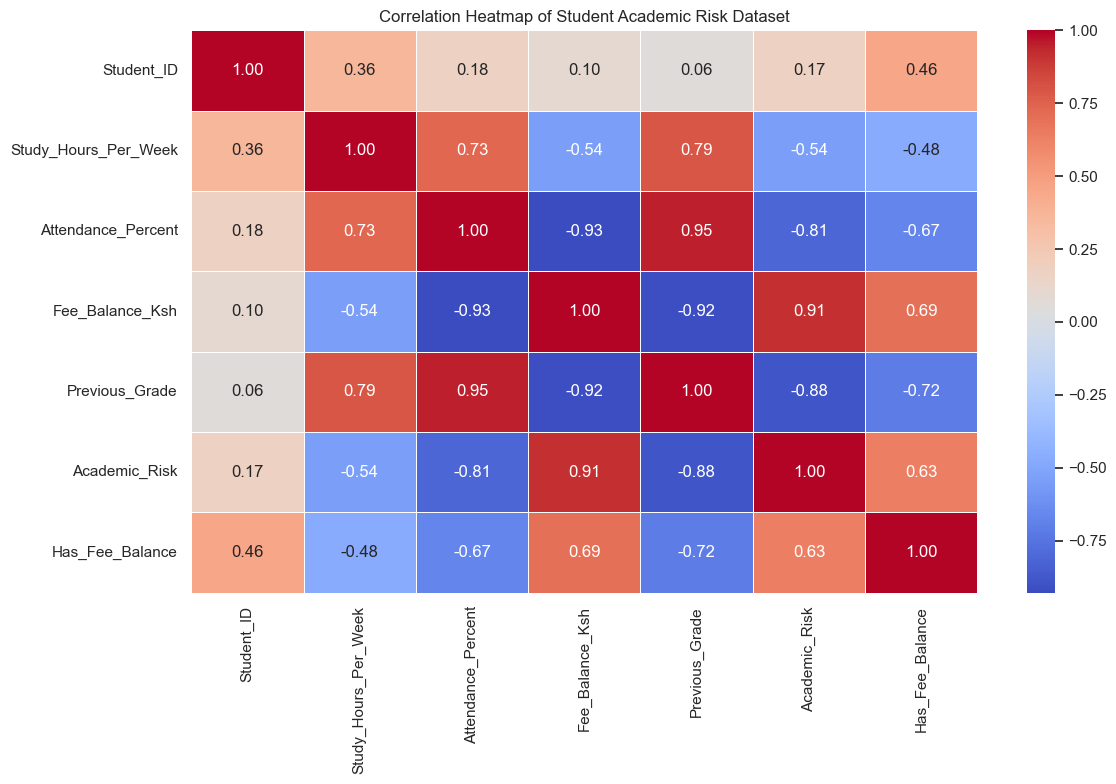

In [35]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(12, 8))

sns.heatmap(
    correlation_matrix,
    annot=True,
    cmap='coolwarm',
    fmt='.2f',
    linewidths=0.5
)

plt.title('Correlation Heatmap of Student Academic Risk Dataset')
plt.tight_layout()
plt.show()

In [36]:
risk_correlations = (
    correlation_matrix['Academic_Risk']
    .drop('Academic_Risk')
    .sort_values(key=abs, ascending=False)
)

risk_correlations

Fee_Balance_Ksh         0.914861
Previous_Grade         -0.884575
Attendance_Percent     -0.811326
Has_Fee_Balance         0.632456
Study_Hours_Per_Week   -0.540896
Student_ID              0.173205
Name: Academic_Risk, dtype: float64

In [37]:
from sklearn.tree import DecisionTreeClassifier, export_graphviz
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, classification_report

print("Decision Tree libraries imported successfully!")

Decision Tree libraries imported successfully!


In [39]:

y = df_encoded['Academic_Risk']


X = df_encoded.drop(
    columns=['Academic_Risk', 'Attendance_Category']
)


X = X.astype(int)

print("Features shape:", X.shape)
print("Target shape:", y.shape)
print("\nTarget values:")
print(y.value_counts().sort_index())

Features shape: (9, 12)
Target shape: (9,)

Target values:
Academic_Risk
0    5
1    4
Name: count, dtype: int64


In [40]:
model = DecisionTreeClassifier(
    max_depth=3,
    random_state=42
)

model.fit(X, y)

print("Decision Tree training completed!")
print("Maximum depth:", model.get_depth())
print("Number of leaves:", model.get_n_leaves())

Decision Tree training completed!
Maximum depth: 1
Number of leaves: 2


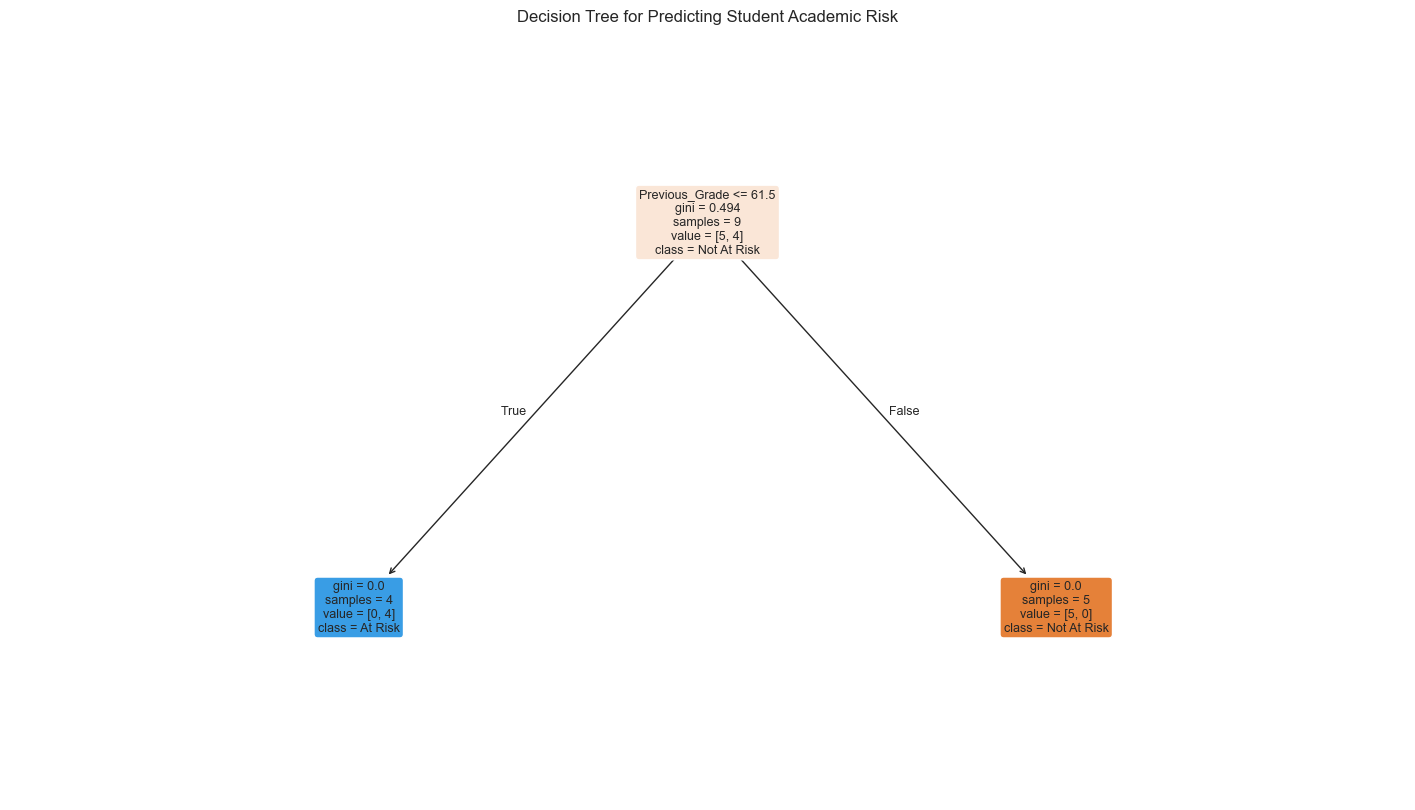

In [41]:
from sklearn.tree import plot_tree
import matplotlib.pyplot as plt

plt.figure(figsize=(18, 10))

plot_tree(
    model,
    feature_names=X.columns,
    class_names=['Not At Risk', 'At Risk'],
    filled=True,
    rounded=True,
    fontsize=9
)

plt.title('Decision Tree for Predicting Student Academic Risk')
plt.show()

In [42]:
root_feature = X.columns[model.tree_.feature[0]]

print("Root decision feature:", root_feature)

Root decision feature: Previous_Grade


In [43]:
import pandas as pd

feature_importance = pd.Series(
    model.feature_importances_,
    index=X.columns
).sort_values(ascending=False)

feature_importance

Previous_Grade              1.0
Student_ID                  0.0
Attendance_Percent          0.0
Study_Hours_Per_Week        0.0
Fee_Balance_Ksh             0.0
Has_Fee_Balance             0.0
County_Kakamega             0.0
County_Nairobi              0.0
County_Nakuru               0.0
County_Narok                0.0
Student_Type_Regular        0.0
Student_Type_Scholarship    0.0
dtype: float64

In [44]:
dot_data = export_graphviz(
    model,
    out_file=None,
    feature_names=X.columns,
    class_names=['Not At Risk', 'At Risk'],
    filled=True,
    rounded=True,
    special_characters=True
)

print(dot_data[:1000])

digraph Tree {
node [shape=box, style="filled, rounded", color="black", fontname="helvetica"] ;
edge [fontname="helvetica"] ;
0 [label=<Previous_Grade &le; 61.5<br/>gini = 0.494<br/>samples = 9<br/>value = [5, 4]<br/>class = Not At Risk>, fillcolor="#fae6d7"] ;
1 [label=<gini = 0.0<br/>samples = 4<br/>value = [0, 4]<br/>class = At Risk>, fillcolor="#399de5"] ;
0 -> 1 [labeldistance=2.5, labelangle=45, headlabel="True"] ;
2 [label=<gini = 0.0<br/>samples = 5<br/>value = [5, 0]<br/>class = Not At Risk>, fillcolor="#e58139"] ;
0 -> 2 [labeldistance=2.5, labelangle=-45, headlabel="False"] ;
}


In [45]:
with open("student_academic_risk_tree.dot", "w", encoding="utf-8") as file:
    file.write(dot_data)

print("Graphviz DOT file saved successfully.")

Graphviz DOT file saved successfully.


In [46]:
root_feature_index = model.tree_.feature[0]
root_feature = X.columns[root_feature_index]

print("Root feature:", root_feature)

Root feature: Previous_Grade


In [47]:

from sklearn.tree import export_text


tree_rules = export_text(model, feature_names=list(X.columns))

print("Decision Tree Rules:")
print(tree_rules)


Decision Tree Rules:
|--- Previous_Grade <= 61.50
|   |--- class: 1
|--- Previous_Grade >  61.50
|   |--- class: 0



In [48]:

import pandas as pd

feature_importance = pd.DataFrame({
    'Feature': X.columns,
    'Importance': model.feature_importances_
})

feature_importance = feature_importance.sort_values(
    by='Importance',
    ascending=False
)

print(feature_importance)



                     Feature  Importance
4             Previous_Grade         1.0
0                 Student_ID         0.0
2         Attendance_Percent         0.0
1       Study_Hours_Per_Week         0.0
3            Fee_Balance_Ksh         0.0
5            Has_Fee_Balance         0.0
6            County_Kakamega         0.0
7             County_Nairobi         0.0
8              County_Nakuru         0.0
9               County_Narok         0.0
10      Student_Type_Regular         0.0
11  Student_Type_Scholarship         0.0
